[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/data-engineering-from-scratch-to-advanced/blob/main/notebooks/topics/07_storage-formats.ipynb)

*Data Engineering from Scratch to Advanced · Notebook 7 of 21*

# Files, Formats & Storage

How data is laid out on disk and why it decides your speed and bill: CSV vs JSON vs Parquet, columnar storage, compression, run-length and dictionary encoding, partitioning, the small-file problem and object storage.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** The same data can cost 40 times more to query, just because of how it's laid out on disk.

**What interviewers really test here:** Parquet vs CSV vs Avro, partition choice, the small file problem and compression.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why file format changes everything *(Basics)*
- [ ] 2. How compression really works *(Core)*
- [ ] 3. Partitioning and the small file problem *(Core)*
- [ ] 4. Object storage, schema changes and tiers *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Picking a format

| Need | Choose |
| --- | --- |
| Analytics tables | Parquet (or ORC), with ZSTD or Snappy |
| Streaming messages | Avro or Protobuf with a schema registry |
| Raw capture of unknown data | JSON Lines, compressed |
| Sharing with people | CSV |
| Updates, deletes, time travel | a table format: Iceberg, Delta, Hudi |

---
# Part 2: Lessons, step by step

## Lesson 1: Why file format changes everything

*Level: Basics*

The same data can cost 40 times more to query, purely because of how it's written.



| Format | Layout | Schema | Speed for analytics | Use |
| --- | --- | --- | --- | --- |
| CSV | text, rows | none | slow | exchange with people |
| JSON Lines | text, rows | none | slow | raw events, nested data |
| Avro | binary, rows | built in | medium | Kafka, writing a row at a time |
| Parquet / ORC | binary, columns | built in | fast | analytics |



**Rows vs columns on disk:**



```text
Row:     1 Asha Pune | 2 Ben Delhi | 3 Chen Pune
Column:  1 2 3 | Asha Ben Chen | Pune Delhi Pune
```



**Query cost example.** 1 TB of data, 50 columns, a query using 5, and Parquet compressing 4 times:



- CSV reads everything: 1,000 GB.
- Parquet: 1000 × 5/50 ÷ 4 = **25 GB**, which is 40 times less.



If your warehouse charges per byte scanned, that's also 40 times cheaper.



**What's inside a Parquet file?** It's split into **row groups**, say 128 MB each. Each holds column chunks, split into pages. The footer stores the schema, plus **min and max values** per chunk. A query for values 15 to 22, with groups covering 1–10, 11–20 and 21–30, can skip the first group without reading it.

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q16](#q16), [Q10](#q10), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 2: How compression really works

*Level: Core*

Columnar files compress well because similar values sit together. Encodings run first, then general compression such as Snappy or ZSTD.



| Encoding | Idea | Example |
| --- | --- | --- |
| Run-length | store value + count | a a a b a → a×3, b×1, a×1 |
| Dictionary | store distinct values once, plus small ids | IN US IN IN → [IN, US] + 0 1 0 0 |
| Delta | store differences | 1000 1001 1003 → 1000, 1, 2 |



**Which wins depends on the data.** With 2,000 values of two letters, stored plainly at 4,000 bytes:



| Data | Plain | RLE (value + 4-byte count) |
| --- | --- | --- |
| IN×1000, US×1000 | 4,000 | **12** |
| a, b, a, b, … alternating | 2,000 | 10,000: worse! |



RLE is amazing on long runs, and it backfires on data with none. Formats pick encodings automatically, per column.



Real dictionary encoding doesn't use 4 bytes per id. Two distinct values need only **1 bit** each, so 1,000 values take 125 bytes.



**Sorting improves compression**, because it creates long runs. The demo compresses 100,000 random city names: about 44,600 bytes shuffled, and just 744 bytes sorted. Real data won't always be this dramatic. Sorting data by a low-cardinality column before writing is a cheap trick that often gives a big saving, and it also improves min/max skipping.



| Codec | Ratio | Speed |
| --- | --- | --- |
| Snappy | lower | very fast |
| ZSTD | high | good: a strong default |
| Gzip | high | slower |

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

raw bytes: 499982
gzip, shuffled: 44610
gzip, sorted:   744


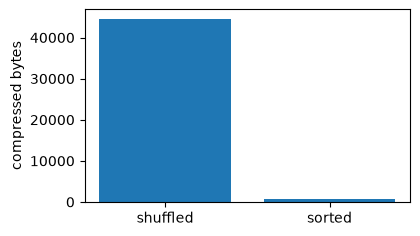

In [2]:
import gzip


def sorting_helps_compression():
    rng = np.random.default_rng(0)
    cities = rng.choice(["Pune", "Delhi", "Goa", "Agra"], 100000).tolist()
    shuffled = len(gzip.compress(",".join(cities).encode(), 6, mtime=0))
    ordered = len(gzip.compress(",".join(sorted(cities)).encode(), 6, mtime=0))
    print("raw bytes:", len(",".join(cities)))
    print("gzip, shuffled:", shuffled)
    print("gzip, sorted:  ", ordered)
    fig, ax = plt.subplots(figsize=(4.2, 2.5))
    ax.bar(["shuffled", "sorted"], [shuffled, ordered])
    ax.set_ylabel("compressed bytes")


sorting_helps_compression()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q4](#q4), [Q8](#q8), [Q20](#q20), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 3: Partitioning and the small file problem

*Level: Core*

**Partitioning** splits a table into folders by a column, so a query can skip whole folders: partition pruning.



```python
lake/orders/year=2026/month=01/day=05/part-0.parquet
```



A query for one day out of three, sized 100, 200 and 300 MB, reads 200 MB, not 600.



**Choosing the column is a real design decision:**



| 1 TB partitioned by | Partitions | Average size | Verdict |
| --- | --- | --- | --- |
| date (1 year) | 365 | 2.74 GB | good |
| country code flag | 2 | 500 GB | too few |
| user id | 10 million | 100 KB | **terrible** |



Partition by what queries filter on, with moderate cardinality. Never by a high-cardinality column like user id.



**The small file problem.** Opening a file has a cost whatever its size. Reading 1 GB with 2 ms per file open and 1 MB per ms:



| Files | Opening | Reading | Total |
| --- | --- | --- | --- |
| 4 | 8 ms | 1,000 ms | about 1 s |
| 10,000 | 20,000 ms | 1,000 ms | **21 s** |



The chart shows this. Streaming jobs and over-partitioned tables often produce thousands of tiny files. The fix is **compaction**, merging them into files of about 128 MB to 1 GB. So 10 GB at 128 MB needs 79 files.



**Bucketing** splits by hash of a column, such as `id % n`, inside partitions. Equal keys are then always in the same bucket number, which makes joins on that key much cheaper, as you'll see in Spark.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

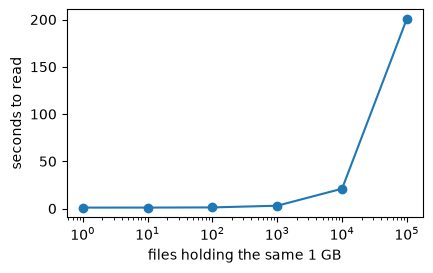

In [3]:
def small_files_chart():
    files = np.array([1, 10, 100, 1000, 10000, 100000])
    fig, ax = plt.subplots(figsize=(4.6, 2.7))
    ax.semilogx(files, (files * 2 + 1000) / 1000, "o-")
    ax.set_xlabel("files holding the same 1 GB")
    ax.set_ylabel("seconds to read")


small_files_chart()

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q11](#q11), [Q12](#q12), [Q13](#q13), [Q6](#q6), [Q7](#q7), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 4: Object storage, schema changes and tiers

*Level: Advanced*

**Object storage** (S3, GCS, Azure Blob) is where lakes live. It's cheap and nearly unlimited, but it's **not a normal disk**:



- A "folder" is just a name prefix, so listing many files is slow.
- You replace whole objects; you can't edit a part of a file.
- A rename is really a copy and a delete, so it isn't atomic for many files. That's why renaming a folder to commit results isn't safe, and table formats exist.



**Separating storage and compute** is the big architectural change of the last decade. Data sits in cheap object storage while compute scales on demand, and you pay for compute only when running.



**Schema evolution.** What can change safely?



| Change | Safe? |
| --- | --- |
| Add an optional column | yes |
| Remove a column | no: readers may need it |
| Rename a column | no: it looks like remove + add |
| Change a type | usually not; widening int to long often is |



**Storage tiers** trade access speed against price. Keep recent data hot and move old data to cold, with lifecycle rules. With made-up prices, 100 GB hot, 200 GB warm and 1,000 GB cold costs 2.3 + 2.5 + 4 = 8.8 a month. Remember that cold tiers often charge for retrieval.



**Verify files.** Keep checksums in a manifest, because files can arrive truncated, and a checksum catches it at once.

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q17](#q17), [Q19](#q19). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Rows to Columns

🟢 Warm-up · *The columnar idea*

Convert a list of dictionaries into a dictionary of column lists.

**Examples**

- `rows = [{'a': 1, 'b': 'x'}, {'a': 2, 'b': 'y'}]` → `{'a': [1, 2], 'b': ['x', 'y']}`

In [ ]:
def to_columns(rows):
    """
    Convert a list of dictionaries into a dictionary of column lists.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(to_columns, [
    (([{'a': 1, 'b': 'x'}, {'a': 2, 'b': 'y'}],), {'a': [1, 2], 'b': ['x', 'y']}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension per column.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Nested loops.

```python
def to_columns(rows):
    out = {}
    for r in rows:
        for k, v in r.items():
            out.setdefault(k, []).append(v)
    return out
```

**Cost:** O(n·c) time, O(n·c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension per column.

```python
def to_columns(rows):
    return {k: [r[k] for r in rows] for k in rows[0]}
```

**Cost:** O(n·c) time, O(n·c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(n·c) time and O(n·c) space."

"I can do better: A comprehension per column. That's O(n·c) time and O(n·c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/rows-to-columns)

<a id="q2"></a>
### Q2. Run-Length Encoding

🟢 Warm-up · *Repeated values shrink*

Encode a list into [value, count] pairs for consecutive runs.

**Examples**

- `values = ['a', 'a', 'a', 'b', 'a']` → `[['a', 3], ['b', 1], ['a', 1]]`
- `values = []` → `[]`

In [ ]:
def rle(values):
    """
    Encode a list into [value, count] pairs for consecutive runs.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rle, [
    ((['a', 'a', 'a', 'b', 'a'],), [['a', 3], ['b', 1], ['a', 1]]),
    (([],), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track the current run.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`itertools.groupby`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Track the current run.

```python
def rle(values):
    out = []
    for v in values:
        if out and out[-1][0] == v:
            out[-1][1] += 1
        else:
            out.append([v, 1])
    return out
```

**Cost:** O(n) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `itertools.groupby`.

```python
def rle(values):
    import itertools
    return [[k, len(list(g))] for k, g in itertools.groupby(values)]
```

**Cost:** O(n) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track the current run. That costs O(n) time and O(r) space."

"I can do better: `itertools.groupby`. That's O(n) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/run-length-encoding)

<a id="q3"></a>
### Q3. Dictionary Encoding

🟢 Warm-up · *Few distinct values*

Return (dictionary of distinct values in first-seen order, list of indices).

**Examples**

- `values = ['IN', 'US', 'IN', 'IN']` → `(['IN', 'US'], [0, 1, 0, 0])`

In [ ]:
def dict_encode(values):
    """
    Return (dictionary of distinct values in first-seen order, list of indices).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dict_encode, [
    ((['IN', 'US', 'IN', 'IN'],), (['IN', 'US'], [0, 1, 0, 0])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

`list.index`.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dictionary for lookups.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** `list.index`.

```python
def dict_encode(values):
    d = []
    ids = []
    for v in values:
        if v not in d:
            d.append(v)
        ids.append(d.index(v))
    return (d, ids)
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dictionary for lookups.

```python
def dict_encode(values):
    index = {}
    ids = [index.setdefault(v, len(index)) for v in values]
    return (list(index), ids)
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: `list.index`. That costs O(n·d) time and O(d) space."

"I can do better: A dictionary for lookups. That's O(n) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/dictionary-encoding)

<a id="q4"></a>
### Q4. Delta Encoding

🟢 Warm-up · *Timestamps compress well*

Store the first value, then differences. Return encoded values, and decode to confirm the round trip.

**Examples**

- `values = [1000, 1001, 1003, 1003]` → `([1000, 1, 2, 0], True)`

In [ ]:
def delta(values):
    """
    Store the first value, then differences. Return encoded values, and decode
    to confirm the round trip.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(delta, [
    (([1000, 1001, 1003, 1003],), ([1000, 1, 2, 0], True)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops both ways.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.diff` and `np.cumsum`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loops both ways.

```python
def delta(values):
    enc = [values[0]]
    for i in range(1, len(values)):
        enc.append(values[i] - values[i - 1])
    dec, total = [], 0
    for d in enc:
        total += d
        dec.append(total)
    return (enc, dec == values)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.diff` and `np.cumsum`.

```python
def delta(values):
    enc = np.concatenate([values[:1], np.diff(values)])
    return (enc, np.cumsum(enc).tolist() == values)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops both ways. That costs O(n) time and O(n) space."

"I can do better: `np.diff` and `np.cumsum`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/delta-encoding)

<a id="q5"></a>
### Q5. Partition Pruning

🟢 Warm-up · *Skip whole folders*

partitions maps a date to file bytes. Return (bytes scanned for a date range, bytes saved vs reading all).

**Examples**

- `partitions = {'d1': 100, 'd2': 200, 'd3': 300}, lo = 'd2', hi = 'd3'` → `(500, 100)`

In [ ]:
def pruning(partitions, lo, hi):
    """
    partitions maps a date to file bytes. Return (bytes scanned for a date
    range, bytes saved vs reading all).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pruning, [
    (({'d1': 100, 'd2': 200, 'd3': 300}, 'd2', 'd3'), (500, 100)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with a comparison.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A generator.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop with a comparison.

```python
def pruning(partitions, lo, hi):
    scanned = total = 0
    for day, size in partitions.items():
        total += size
        if lo <= day <= hi:
            scanned += size
    return (scanned, total - scanned)
```

**Cost:** O(p) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A generator.

```python
def pruning(partitions, lo, hi):
    scanned = sum(s for d, s in partitions.items() if lo <= d <= hi)
    return (scanned, sum(partitions.values()) - scanned)
```

**Cost:** O(p) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with a comparison. That costs O(p) time and O(1) space."

"I can do better: A generator. That's O(p) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/partition-pruning)

<a id="q6"></a>
### Q6. How Many Output Files?

🟢 Warm-up · *Sizing a write*

Return files needed for data\_gb at target\_mb per file (GB = 1000 MB), rounded up.

**Examples**

- `data_gb = 10, target_mb = 128` → `79`
- `data_gb = 1, target_mb = 1000` → `1`

In [ ]:
def file_count(data_gb, target_mb):
    """
    Return files needed for data_gb at target_mb per file (GB = 1000 MB),
    rounded up.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(file_count, [
    ((10, 128), 79),
    ((1, 1000), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Integer arithmetic with a remainder check.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.ceil`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Integer arithmetic with a remainder check.

```python
def file_count(data_gb, target_mb):
    total = data_gb * 1000
    n = total // target_mb
    return n + 1 if total % target_mb else n
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `math.ceil`.

```python
def file_count(data_gb, target_mb):
    return math.ceil(data_gb * 1000 / target_mb)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Integer arithmetic with a remainder check. That costs O(1) time and O(1) space."

"I can do better: `math.ceil`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/how-many-output-files)

<a id="q7"></a>
### Q7. Hive-Style Partition Paths

🟢 Warm-up · *Parse them back*

Parse 'lake/t/year=2026/month=01/part-0.parquet' into a dictionary of partition values, in order.

**Examples**

- `path = 'lake/t/year=2026/month=01/part-0.parquet'` → `{'year': '2026', 'month': '01'}`

In [ ]:
def parse_partitions(path):
    """
    Parse 'lake/t/year=2026/month=01/part-0.parquet' into a dictionary of
    partition values, in order.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(parse_partitions, [
    (('lake/t/year=2026/month=01/part-0.parquet',), {'year': '2026', 'month': '01'}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Split on / and check for =.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A regular expression.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Split on / and check for =.

```python
def parse_partitions(path):
    out = {}
    for part in path.split("/"):
        if "=" in part:
            key, value = part.split("=", 1)
            out[key] = value
    return out
```

**Cost:** O(n) time, O(p) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A regular expression.

```python
def parse_partitions(path):
    import re
    return dict(re.findall(r"([^/=]+)=([^/]+)", path))
```

**Cost:** O(n) time, O(p) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Split on / and check for =. That costs O(n) time and O(p) space."

"I can do better: A regular expression. That's O(n) time and O(p) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/hive-style-partition-paths)

<a id="q8"></a>
### Q8. Encoded Size Comparison

🟡 Interview standard · *Which encoding wins?*

With ints at 4 bytes and strings at their length, return bytes for plain storage, dictionary encoding (strings once, 4 per index) and RLE (string + 4 per run).

**Examples**

- `values = ['IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US']` → `(4000, 8004, 12)`
- `values = ['a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b']` → `(2000, 8002, 10000)`

In [ ]:
def encoding_sizes(values):
    """
    With ints at 4 bytes and strings at their length, return bytes for plain
    storage, dictionary encoding (strings once, 4 per index) and RLE (string + 4
    per run).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(encoding_sizes, [
    ((['IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'IN', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US', 'US'],), (4000, 8004, 12)),
    ((['a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b', 'a', 'b'],), (2000, 8002, 10000)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Built-ins, and groupby.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute each in a loop.

```python
def encoding_sizes(values):
    plain = 0
    for v in values:
        plain += len(v)
    distinct = []
    for v in values:
        if v not in distinct:
            distinct.append(v)
    dictionary = sum(len(v) for v in distinct) + 4 * len(values)
    rle_size, prev = 0, None
    for v in values:
        if v != prev:
            rle_size += len(v) + 4
            prev = v
    return (plain, dictionary, rle_size)
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Built-ins, and groupby.

```python
def encoding_sizes(values):
    import itertools
    runs = [k for k, _ in itertools.groupby(values)]
    return (sum(map(len, values)), sum(map(len, set(values))) + 4 * len(values), sum(len(r) + 4 for r in runs))
```

**Cost:** O(n) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each in a loop. That costs O(n) time and O(d) space."

"I can do better: Built-ins, and groupby. That's O(n) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/encoded-size-comparison)

<a id="q9"></a>
### Q9. Sorted Data Compresses Better

🟡 Interview standard · *Order matters*

Return whether gzip output is smaller when the values are sorted first, using a fixed level and no timestamp.

**Examples**

- `values = ['0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81']` → `True`

In [ ]:
import gzip

def sorted_is_smaller(values):
    """
    Return whether gzip output is smaller when the values are sorted first,
    using a fixed level and no timestamp.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sorted_is_smaller, [
    ((['0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81', '0', '919', '838', '757', '676', '595', '514', '433', '352', '271', '190', '109', '28', '947', '866', '785', '704', '623', '542', '461', '380', '299', '218', '137', '56', '975', '894', '813', '732', '651', '570', '489', '408', '327', '246', '165', '84', '3', '922', '841', '760', '679', '598', '517', '436', '355', '274', '193', '112', '31', '950', '869', '788', '707', '626', '545', '464', '383', '302', '221', '140', '59', '978', '897', '816', '735', '654', '573', '492', '411', '330', '249', '168', '87', '6', '925', '844', '763', '682', '601', '520', '439', '358', '277', '196', '115', '34', '953', '872', '791', '710', '629', '548', '467', '386', '305', '224', '143', '62', '981', '900', '819', '738', '657', '576', '495', '414', '333', '252', '171', '90', '9', '928', '847', '766', '685', '604', '523', '442', '361', '280', '199', '118', '37', '956', '875', '794', '713', '632', '551', '470', '389', '308', '227', '146', '65', '984', '903', '822', '741', '660', '579', '498', '417', '336', '255', '174', '93', '12', '931', '850', '769', '688', '607', '526', '445', '364', '283', '202', '121', '40', '959', '878', '797', '716', '635', '554', '473', '392', '311', '230', '149', '68', '987', '906', '825', '744', '663', '582', '501', '420', '339', '258', '177', '96', '15', '934', '853', '772', '691', '610', '529', '448', '367', '286', '205', '124', '43', '962', '881', '800', '719', '638', '557', '476', '395', '314', '233', '152', '71', '990', '909', '828', '747', '666', '585', '504', '423', '342', '261', '180', '99', '18', '937', '856', '775', '694', '613', '532', '451', '370', '289', '208', '127', '46', '965', '884', '803', '722', '641', '560', '479', '398', '317', '236', '155', '74', '993', '912', '831', '750', '669', '588', '507', '426', '345', '264', '183', '102', '21', '940', '859', '778', '697', '616', '535', '454', '373', '292', '211', '130', '49', '968', '887', '806', '725', '644', '563', '482', '401', '320', '239', '158', '77', '996', '915', '834', '753', '672', '591', '510', '429', '348', '267', '186', '105', '24', '943', '862', '781', '700', '619', '538', '457', '376', '295', '214', '133', '52', '971', '890', '809', '728', '647', '566', '485', '404', '323', '242', '161', '80', '999', '918', '837', '756', '675', '594', '513', '432', '351', '270', '189', '108', '27', '946', '865', '784', '703', '622', '541', '460', '379', '298', '217', '136', '55', '974', '893', '812', '731', '650', '569', '488', '407', '326', '245', '164', '83', '2', '921', '840', '759', '678', '597', '516', '435', '354', '273', '192', '111', '30', '949', '868', '787', '706', '625', '544', '463', '382', '301', '220', '139', '58', '977', '896', '815', '734', '653', '572', '491', '410', '329', '248', '167', '86', '5', '924', '843', '762', '681', '600', '519', '438', '357', '276', '195', '114', '33', '952', '871', '790', '709', '628', '547', '466', '385', '304', '223', '142', '61', '980', '899', '818', '737', '656', '575', '494', '413', '332', '251', '170', '89', '8', '927', '846', '765', '684', '603', '522', '441', '360', '279', '198', '117', '36', '955', '874', '793', '712', '631', '550', '469', '388', '307', '226', '145', '64', '983', '902', '821', '740', '659', '578', '497', '416', '335', '254', '173', '92', '11', '930', '849', '768', '687', '606', '525', '444', '363', '282', '201', '120', '39', '958', '877', '796', '715', '634', '553', '472', '391', '310', '229', '148', '67', '986', '905', '824', '743', '662', '581', '500', '419', '338', '257', '176', '95', '14', '933', '852', '771', '690', '609', '528', '447', '366', '285', '204', '123', '42', '961', '880', '799', '718', '637', '556', '475', '394', '313', '232', '151', '70', '989', '908', '827', '746', '665', '584', '503', '422', '341', '260', '179', '98', '17', '936', '855', '774', '693', '612', '531', '450', '369', '288', '207', '126', '45', '964', '883', '802', '721', '640', '559', '478', '397', '316', '235', '154', '73', '992', '911', '830', '749', '668', '587', '506', '425', '344', '263', '182', '101', '20', '939', '858', '777', '696', '615', '534', '453', '372', '291', '210', '129', '48', '967', '886', '805', '724', '643', '562', '481', '400', '319', '238', '157', '76', '995', '914', '833', '752', '671', '590', '509', '428', '347', '266', '185', '104', '23', '942', '861', '780', '699', '618', '537', '456', '375', '294', '213', '132', '51', '970', '889', '808', '727', '646', '565', '484', '403', '322', '241', '160', '79', '998', '917', '836', '755', '674', '593', '512', '431', '350', '269', '188', '107', '26', '945', '864', '783', '702', '621', '540', '459', '378', '297', '216', '135', '54', '973', '892', '811', '730', '649', '568', '487', '406', '325', '244', '163', '82', '1', '920', '839', '758', '677', '596', '515', '434', '353', '272', '191', '110', '29', '948', '867', '786', '705', '624', '543', '462', '381', '300', '219', '138', '57', '976', '895', '814', '733', '652', '571', '490', '409', '328', '247', '166', '85', '4', '923', '842', '761', '680', '599', '518', '437', '356', '275', '194', '113', '32', '951', '870', '789', '708', '627', '546', '465', '384', '303', '222', '141', '60', '979', '898', '817', '736', '655', '574', '493', '412', '331', '250', '169', '88', '7', '926', '845', '764', '683', '602', '521', '440', '359', '278', '197', '116', '35', '954', '873', '792', '711', '630', '549', '468', '387', '306', '225', '144', '63', '982', '901', '820', '739', '658', '577', '496', '415', '334', '253', '172', '91', '10', '929', '848', '767', '686', '605', '524', '443', '362', '281', '200', '119', '38', '957', '876', '795', '714', '633', '552', '471', '390', '309', '228', '147', '66', '985', '904', '823', '742', '661', '580', '499', '418', '337', '256', '175', '94', '13', '932', '851', '770', '689', '608', '527', '446', '365', '284', '203', '122', '41', '960', '879', '798', '717', '636', '555', '474', '393', '312', '231', '150', '69', '988', '907', '826', '745', '664', '583', '502', '421', '340', '259', '178', '97', '16', '935', '854', '773', '692', '611', '530', '449', '368', '287', '206', '125', '44', '963', '882', '801', '720', '639', '558', '477', '396', '315', '234', '153', '72', '991', '910', '829', '748', '667', '586', '505', '424', '343', '262', '181', '100', '19', '938', '857', '776', '695', '614', '533', '452', '371', '290', '209', '128', '47', '966', '885', '804', '723', '642', '561', '480', '399', '318', '237', '156', '75', '994', '913', '832', '751', '670', '589', '508', '427', '346', '265', '184', '103', '22', '941', '860', '779', '698', '617', '536', '455', '374', '293', '212', '131', '50', '969', '888', '807', '726', '645', '564', '483', '402', '321', '240', '159', '78', '997', '916', '835', '754', '673', '592', '511', '430', '349', '268', '187', '106', '25', '944', '863', '782', '701', '620', '539', '458', '377', '296', '215', '134', '53', '972', '891', '810', '729', '648', '567', '486', '405', '324', '243', '162', '81'],), True),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compress both, comparing the lengths.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper used twice.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compress both, comparing the lengths.

```python
def sorted_is_smaller(values):
    original = gzip.compress(",".join(values).encode(), 6, mtime=0)
    ordered = gzip.compress(",".join(sorted(values)).encode(), 6, mtime=0)
    return len(ordered) < len(original)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper used twice.

```python
def sorted_is_smaller(values):
    size = lambda v: len(gzip.compress(",".join(v).encode(), 6, mtime=0))
    return size(sorted(values)) < size(values)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compress both, comparing the lengths. That costs O(n log n) time and O(n) space."

"I can do better: A helper used twice. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/sorted-data-compresses-better)

<a id="q10"></a>
### Q10. Min/Max Skipping

🟡 Interview standard · *Row group statistics*

Each row group has min and max for a column. Return indices of groups that could contain values in [lo, hi]. Parquet readers do this.

**Examples**

- `groups = [(1, 10), (11, 20), (21, 30)], lo = 15, hi = 22` → `[1, 2]`
- `groups = [(1, 5)], lo = 9, hi = 10` → `[]`

In [ ]:
def skip_groups(groups, lo, hi):
    """
    Each row group has min and max for a column. Return indices of groups that
    could contain values in [lo, hi]. Parquet readers do this.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(skip_groups, [
    (([(1, 10), (11, 20), (21, 30)], 15, 22), [1, 2]),
    (([(1, 5)], 9, 10), []),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compare in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compare in a loop.

```python
def skip_groups(groups, lo, hi):
    out = []
    for i, (a, b) in enumerate(groups):
        if not (b < lo or a > hi):
            out.append(i)
    return out
```

**Cost:** O(g) time, O(g) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def skip_groups(groups, lo, hi):
    return [i for i, (a, b) in enumerate(groups) if a <= hi and b >= lo]
```

**Cost:** O(g) time, O(g) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compare in a loop. That costs O(g) time and O(g) space."

"I can do better: A comprehension. That's O(g) time and O(g) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/min-max-skipping)

<a id="q11"></a>
### Q11. Choosing a Partition Column

🟡 Interview standard · *Too few or too many*

Given total GB and the distinct values of a column, return average GB per partition rounded to 3 decimals, and 'good' if between 0.1 and 100, 'too many' if below, 'too few' if above.

**Examples**

- `gb = 1000, distinct = 365` → `(2.74, 'good')`
- `gb = 1000, distinct = 2` → `(500.0, 'too few')`
- `gb = 1000, distinct = 10000000` → `(0.0, 'too many')`

In [ ]:
def partition_check(gb, distinct):
    """
    Given total GB and the distinct values of a column, return average GB per
    partition rounded to 3 decimals, and 'good' if between 0.1 and 100, 'too
    many' if below, 'too few' if above.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(partition_check, [
    ((1000, 365), (2.74, 'good')),
    ((1000, 2), (500.0, 'too few')),
    ((1000, 10000000), (0.0, 'too many')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Compact.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs.

```python
def partition_check(gb, distinct):
    avg = gb / distinct
    if avg < 0.1:
        verdict = "too many"
    elif avg > 100:
        verdict = "too few"
    else:
        verdict = "good"
    return (round(avg, 3), verdict)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Compact.

```python
def partition_check(gb, distinct):
    avg = gb / distinct
    return (round(avg, 3), "too many" if avg < 0.1 else "too few" if avg > 100 else "good")
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs. That costs O(1) time and O(1) space."

"I can do better: Compact. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/choosing-a-partition-column)

<a id="q12"></a>
### Q12. The Small File Problem

🟡 Interview standard · *Metadata overhead*

Each file costs a fixed open time in ms plus reading at mb\_per\_ms. Return total ms for total\_mb split into n files, rounded to 1 decimal.

**Examples**

- `total_mb = 1000, n = 10000, open_ms = 2, mb_per_ms = 1` → `21000.0`
- `total_mb = 1000, n = 4, open_ms = 2, mb_per_ms = 1` → `1008.0`

In [ ]:
def read_time(total_mb, n, open_ms, mb_per_ms):
    """
    Each file costs a fixed open time in ms plus reading at mb_per_ms. Return
    total ms for total_mb split into n files, rounded to 1 decimal.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(read_time, [
    ((1000, 10000, 2, 1), 21000.0),
    ((1000, 4, 2, 1), 1008.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

One line.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Step by step.

```python
def read_time(total_mb, n, open_ms, mb_per_ms):
    opening = n * open_ms
    reading = total_mb / mb_per_ms
    return round(opening + reading, 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** One line.

```python
def read_time(total_mb, n, open_ms, mb_per_ms):
    return round(n * open_ms + total_mb / mb_per_ms, 1)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Step by step. That costs O(1) time and O(1) space."

"I can do better: One line. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/the-small-file-problem)

<a id="q13"></a>
### Q13. Compact Small Files

🟡 Interview standard · *Merge into target size*

Greedily group file sizes in order into outputs of at most target MB. Return group sizes.

**Examples**

- `sizes = [10, 40, 80, 20, 100, 5], target = 128` → `[50, 100, 105]`

In [ ]:
def compact(sizes, target):
    """
    Greedily group file sizes in order into outputs of at most target MB. Return
    group sizes.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(compact, [
    (([10, 40, 80, 20, 100, 5], 128), [50, 100, 105]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build lists, then sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A running total.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Build lists, then sum.

```python
def compact(sizes, target):
    groups, current = [], []
    for s in sizes:
        if current and sum(current) + s > target:
            groups.append(sum(current))
            current = []
        current.append(s)
    if current:
        groups.append(sum(current))
    return groups
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A running total.

```python
def compact(sizes, target):
    out, cur = [], 0
    for s in sizes:
        if cur and cur + s > target:
            out.append(cur)
            cur = 0
        cur += s
    return out + [cur] if cur else out
```

**Cost:** O(n) time, O(g) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build lists, then sum. That costs O(n) time and O(n) space."

"I can do better: A running total. That's O(n) time and O(g) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/compact-small-files)

<a id="q14"></a>
### Q14. Schema Evolution: What's Safe?

🟡 Interview standard · *Change without breaking readers*

Compare old and new schemas (column → type). Return (added, removed, changed types), each sorted, and whether it's safe: no removed or changed columns.

**Examples**

- `old = {'id': 'int', 'a': 'str'}, new = {'id': 'int', 'a': 'str', 'b': 'int'}` → `(['b'], [], [], True)`
- `old = {'id': 'int', 'a': 'str'}, new = {'id': 'str'}` → `([], ['a'], ['id'], False)`

In [ ]:
def schema_change(old, new):
    """
    Compare old and new schemas (column → type). Return (added, removed, changed
    types), each sorted, and whether it's safe: no removed or changed columns.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(schema_change, [
    (({'id': 'int', 'a': 'str'}, {'id': 'int', 'a': 'str', 'b': 'int'}), (['b'], [], [], True)),
    (({'id': 'int', 'a': 'str'}, {'id': 'str'}), ([], ['a'], ['id'], False)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over both.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set operations.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Loops over both.

```python
def schema_change(old, new):
    added, removed, changed = [], [], []
    for c in new:
        if c not in old:
            added.append(c)
    for c in old:
        if c not in new:
            removed.append(c)
        elif old[c] != new[c]:
            changed.append(c)
    return (sorted(added), sorted(removed), sorted(changed), not removed and not changed)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set operations.

```python
def schema_change(old, new):
    added, removed = sorted(new.keys() - old.keys()), sorted(old.keys() - new.keys())
    changed = sorted(c for c in old.keys() & new.keys() if old[c] != new[c])
    return (added, removed, changed, not removed and not changed)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over both. That costs O(c) time and O(c) space."

"I can do better: Set operations. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/schema-evolution-whats-safe)

<a id="q15"></a>
### Q15. Bucket for Sampling and Joins

🟡 Interview standard · *Hash partitioning*

Assign ids to n buckets as id % n, and return the size of each bucket.

**Examples**

- `ids = [1, 2, 3, 4, 5, 6, 7], n = 3` → `[2, 3, 2]`

In [ ]:
def bucket_sizes(ids, n):
    """
    Assign ids to n buckets as id % n, and return the size of each bucket.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bucket_sizes, [
    (([1, 2, 3, 4, 5, 6, 7], 3), [2, 3, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A list of counters.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.bincount`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A list of counters.

```python
def bucket_sizes(ids, n):
    counts = [0] * n
    for i in ids:
        counts[i % n] += 1
    return counts
```

**Cost:** O(k) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.bincount`.

```python
def bucket_sizes(ids, n):
    return np.bincount(np.array(ids) % n, minlength=n)
```

**Cost:** O(k) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A list of counters. That costs O(k) time and O(n) space."

"I can do better: `np.bincount`. That's O(k) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/bucket-for-sampling-and-joins)

<a id="q16"></a>
### Q16. Compare Query Cost by Format

🟡 Interview standard · *Priced per byte scanned*

A query reads use\_cols of cols on data\_gb. CSV scans everything; Parquet reads the used share, then compression ratio applies. Return the GB scanned in each, rounded to 2 decimals.

**Examples**

- `data_gb = 1000, cols = 50, use_cols = 5, ratio = 4` → `(1000, 25.0)`

In [ ]:
def scan_by_format(data_gb, cols, use_cols, ratio):
    """
    A query reads use_cols of cols on data_gb. CSV scans everything; Parquet
    reads the used share, then compression ratio applies. Return the GB scanned
    in each, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scan_by_format, [
    ((1000, 50, 5, 4), (1000, 25.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Formulas.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Compute each.

```python
def scan_by_format(data_gb, cols, use_cols, ratio):
    csv_scan = data_gb
    share = use_cols / cols
    parquet = data_gb * share
    parquet = parquet / ratio
    return (round(csv_scan, 2), round(parquet, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Formulas.

```python
def scan_by_format(data_gb, cols, use_cols, ratio):
    return (round(data_gb, 2), round(data_gb * use_cols / cols / ratio, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each. That costs O(1) time and O(1) space."

"I can do better: Formulas. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/compare-query-cost-by-format)

<a id="q17"></a>
### Q17. Storage Tier Choice

🟡 Interview standard · *Hot, warm, cold*

Given days since last access, return 'hot' under 30, 'warm' under 180, otherwise 'cold'. Then return total cost, with made-up per-GB prices hot 0.023, warm 0.0125, cold 0.004. Items are (days, gb); round to 3 decimals.

**Examples**

- `items = [(5, 100), (60, 200), (400, 1000)]` → `(['hot', 'warm', 'cold'], 8.8)`

In [ ]:
def tier_cost(items):
    """
    Given days since last access, return 'hot' under 30, 'warm' under 180,
    otherwise 'cold'. Then return total cost, with made-up per-GB prices hot
    0.023, warm 0.0125, cold 0.004. Items are (days, gb); round to 3 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tier_cost, [
    (([(5, 100), (60, 200), (400, 1000)],), (['hot', 'warm', 'cold'], 8.8)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ifs in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Ifs in a loop.

```python
def tier_cost(items):
    tiers, cost = [], 0.0
    for days, gb in items:
        if days < 30:
            tiers.append("hot")
            cost += gb * 0.023
        elif days < 180:
            tiers.append("warm")
            cost += gb * 0.0125
        else:
            tiers.append("cold")
            cost += gb * 0.004
    return (tiers, round(cost, 3))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper.

```python
def tier_cost(items):
    price = {"hot": 0.023, "warm": 0.0125, "cold": 0.004}
    tier = lambda d: "hot" if d < 30 else "warm" if d < 180 else "cold"
    tiers = [tier(d) for d, _ in items]
    return (tiers, round(sum(price[t] * g for t, (_, g) in zip(tiers, items)), 3))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ifs in a loop. That costs O(n) time and O(n) space."

"I can do better: A helper. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/storage-tier-choice)

<a id="q18"></a>
### Q18. Nested to Parquet-Friendly

🟡 Interview standard · *Explode arrays*

Rows have an id and a list of items. Return one row per item (explode), and rows with empty lists keep one row with item None.

**Examples**

- `rows = [{'id': 1, 'items': ['a', 'b']}, {'id': 2, 'items': []}]` → `[{'id': 1, 'item': 'a'}, {'id': 1, 'item': 'b'}, {'id': 2, 'item': None}]`

In [ ]:
def explode(rows):
    """
    Rows have an id and a list of items. Return one row per item (explode), and
    rows with empty lists keep one row with item None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(explode, [
    (([{'id': 1, 'items': ['a', 'b']}, {'id': 2, 'items': []}],), [{'id': 1, 'item': 'a'}, {'id': 1, 'item': 'b'}, {'id': 2, 'item': None}]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension using `or [None]`.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Nested loops with an if.

```python
def explode(rows):
    out = []
    for r in rows:
        if r["items"]:
            for item in r["items"]:
                out.append({"id": r["id"], "item": item})
        else:
            out.append({"id": r["id"], "item": None})
    return out
```

**Cost:** O(total) time, O(total) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension using `or [None]`.

```python
def explode(rows):
    return [{"id": r["id"], "item": i} for r in rows for i in (r["items"] or [None])]
```

**Cost:** O(total) time, O(total) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops with an if. That costs O(total) time and O(total) space."

"I can do better: A comprehension using `or [None]`. That's O(total) time and O(total) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/nested-to-parquet-friendly)

<a id="q19"></a>
### Q19. Checksums Catch Corruption

🟡 Interview standard · *Trust, but verify*

manifest maps a file name to its expected md5. Return names whose content doesn't match, sorted.

**Examples**

- `files = {'a.csv': '1,2', 'b.csv': '3,4'}, manifest = {'a.csv': '05cf281c050be3da4eecf3bc6e8aac1b', 'b.csv': 'x'}` → `['b.csv']`

In [ ]:
def corrupt_files(files, manifest):
    """
    manifest maps a file name to its expected md5. Return names whose content
    doesn't match, sorted.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(corrupt_files, [
    (({'a.csv': '1,2', 'b.csv': '3,4'}, {'a.csv': '05cf281c050be3da4eecf3bc6e8aac1b', 'b.csv': 'x'}), ['b.csv']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** A loop.

```python
def corrupt_files(files, manifest):
    import hashlib
    bad = []
    for name, text in files.items():
        if hashlib.md5(text.encode()).hexdigest() != manifest[name]:
            bad.append(name)
    return sorted(bad)
```

**Cost:** O(bytes) time, O(f) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def corrupt_files(files, manifest):
    import hashlib
    return sorted(n for n, t in files.items() if hashlib.md5(t.encode()).hexdigest() != manifest[n])
```

**Cost:** O(bytes) time, O(f) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(bytes) time and O(f) space."

"I can do better: A comprehension. That's O(bytes) time and O(f) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/checksums-catch-corruption)

<a id="q20"></a>
### Q20. Bit-Width of a Dictionary

🟡 Interview standard · *Why real encodings are tiny*

Dictionary indices need ⌈log₂(d)⌉ bits (at least 1). Return bits per value, and bytes for n values, rounded up.

**Examples**

- `d = 2, n = 1000` → `[1, 125]`
- `d = 200, n = 1000` → `[8, 1000]`
- `d = 1, n = 10` → `[1, 2]`

In [ ]:
def bit_width(d, n):
    """
    Dictionary indices need ⌈log₂(d)⌉ bits (at least 1). Return bits per value,
    and bytes for n values, rounded up.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(bit_width, [((2, 1000), [1, 125]), ((200, 1000), [8, 1000]), ((1, 10), [1, 2])], post=list)

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Double in a loop until d fits.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A logarithm.

</details>

<details>
<summary><b>✅ Answer: Step by step</b></summary>

**Idea:** Double in a loop until d fits.

```python
def bit_width(d, n):
    bits, capacity = 1, 2
    while capacity < d:
        capacity *= 2
        bits += 1
    return (bits, math.ceil(n * bits / 8))
```

**Cost:** O(log d) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A logarithm.

```python
def bit_width(d, n):
    bits = max(1, math.ceil(math.log2(d))) if d > 1 else 1
    return (bits, math.ceil(n * bits / 8))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Double in a loop until d fits. That costs O(log d) time and O(1) space."

"I can do better: A logarithm. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/data-engineering-from-scratch-to-advanced/course/#/q/storage-formats/bit-width-of-a-dictionary)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why is Parquet faster than CSV?</b></summary>

It's columnar, so it reads only needed columns. It compresses better, stores types, and keeps min/max statistics that let readers skip data.

</details>

<details>
<summary><b>2. Avro vs Parquet?</b></summary>

Avro is row-based, suited to writing records one at a time, as in Kafka. Parquet is columnar, suited to analytic reads.

</details>

<details>
<summary><b>3. What is partition pruning?</b></summary>

Skipping entire partitions that a filter rules out, so the engine never reads those files.

</details>

<details>
<summary><b>4. Partitioning vs bucketing?</b></summary>

Partitioning creates folders by value, helping filters on a moderate-cardinality column. Bucketing splits by a hash into a fixed number of files, helping joins and high-cardinality keys.

</details>

<details>
<summary><b>5. What's the small file problem, and how do you fix it?</b></summary>

Many tiny files add per-file open and metadata costs. Fix with compaction, sensible partitioning, and repartitioning before writing.

</details>

<details>
<summary><b>6. Why isn't S3 a normal file system?</b></summary>

Objects are written whole, listing is slow, and renames aren't atomic. That's why table formats keep their own metadata.

</details>

<details>
<summary><b>7. Scenario: a daily job's query cost suddenly tripled. Where do you look?</b></summary>

A filter on the partition column may have been lost, a function may be wrapping it, or someone added SELECT \*. Compare bytes scanned with the query plan.

</details>

<details>
<summary><b>8. Scenario: a streaming job produced 500,000 tiny files. What now?</b></summary>

Compact them in a background job, then increase the trigger interval or file target size. A table format's compaction action can do this safely.

</details>

<details>
<summary><b>9. Scenario: someone partitioned a table by user\_id. What's wrong?</b></summary>

Millions of tiny partitions, with huge metadata overhead. Partition by date instead, and bucket or sort by user\_id.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why file format changes everything
- [ ] I can explain: How compression really works
- [ ] I can explain: Partitioning and the small file problem
- [ ] I can explain: Object storage, schema changes and tiers

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Compare Query Cost by Format
- [ ] [Q17](#q17) Storage Tier Choice
- [ ] [Q18](#q18) Nested to Parquet-Friendly
- [ ] [Q19](#q19) Checksums Catch Corruption
- [ ] [Q20](#q20) Bit-Width of a Dictionary

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.